# Auspify ML internship: Netflix titles
Happiness Micheal Ogunji | Machine Learning Intern | Offer ID AT/INT/2039814

Four tasks on one dataset (`netflix_titles.csv`, 8,790 titles): a recommender (Task 1), a rating classifier (Task 3), a forecast of monthly additions (Task 5) and an analytics engine (Task 6). Run top to bottom. The rating classifier search takes about 10 minutes on one CPU core.

Libraries: pandas, numpy, scipy, scikit-learn, statsmodels, matplotlib, pandera, fastapi, httpx, jinja2, joblib.

In [1]:
from collections import Counter
from fastapi import FastAPI, HTTPException, Query
from functools import lru_cache
from jinja2 import Template
from pathlib import Path
from scipy import sparse
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfTransformer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import Ridge
from sklearn.metrics import RocCurveDisplay, accuracy_score, confusion_matrix, f1_score, roc_auc_score
from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, cross_val_predict, cross_validate, train_test_split
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MultiLabelBinarizer, normalize
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder
from sklearn.tree import DecisionTreeClassifier
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
import base64
import io
import joblib
import json
import logging
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pandera.pandas as pa
import time
import warnings
from IPython.display import Image, Markdown, display
from fastapi.testclient import TestClient

warnings.filterwarnings("ignore")
logging.basicConfig(level=logging.INFO, format="%(asctime)s %(name)s %(message)s", force=True)
logging.getLogger("httpx").setLevel(logging.WARNING)
logger = logging.getLogger("recommender")
pd.set_option("display.width", 200)

/usr/local/lib/python3.12/dist-packages/fastapi/testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient as TestClient  # noqa


## Task 1: Content recommender
Recommends similar titles from genre, country, director, type, rating and decade. The data is schema-checked first. Each attribute becomes a block of weighted tags, all blocks are stacked into one unit-length matrix so similarity is a dot product, and the result is tested by hiding a genre and checking whether it comes back.

In [2]:
DATA = Path("netflix_titles.csv")

SEED = 42

K = 10

MISSING = "Not Given"

WEIGHTS = {"genre": 1.0, "country": 1.0, "director": 0.5, "type": 0.5, "rating": 0.5, "decade": 0.25}

logger = logging.getLogger("recommender")

schema = pa.DataFrameSchema(
    {
        "show_id": pa.Column(str, unique=True),
        "type": pa.Column(str, pa.Check.isin(["Movie", "TV Show"])),
        "title": pa.Column(str, pa.Check.str_length(min_value=1)),
        "director": pa.Column(str),
        "country": pa.Column(str),
        "date_added": pa.Column(str),
        "release_year": pa.Column(int, pa.Check.in_range(1900, 2026)),
        "rating": pa.Column(str, pa.Check.str_length(min_value=1)),
        "duration": pa.Column(str),
        "listed_in": pa.Column(str, pa.Check.str_length(min_value=1)),
    },
    strict=True,
)

def split_tags(series):
    cleaned = series.where(series != MISSING, "")
    return cleaned.map(lambda s: [t.strip() for t in s.split(",") if t.strip()])

def load_catalog(path=DATA):
    df = schema.validate(pd.read_csv(path)).reset_index(drop=True)
    df["genres"] = split_tags(df["listed_in"])
    df["countries"] = split_tags(df["country"])
    df["directors"] = split_tags(df["director"])
    df["decade"] = (df["release_year"] // 10 * 10).astype(str)
    return df

class TagBlock:
    def __init__(self, lists, weight, use_idf=True):
        self.binarizer = MultiLabelBinarizer(sparse_output=True)
        self.counts = self.binarizer.fit_transform(lists).astype(np.float32).tocsr()
        self.idf = TfidfTransformer(norm="l2").fit(self.counts) if use_idf else None
        self.scale = np.sqrt(weight)
        self.matrix = self.encode(self.counts)

    def encode(self, counts):
        encoded = self.idf.transform(counts) if self.idf else normalize(counts)
        return encoded.tocsr() * self.scale

class Recommender:
    def __init__(self, df):
        self.df = df
        single = lambda col: df[col].map(lambda x: [x])
        self.blocks = {
            "genre": TagBlock(df["genres"], WEIGHTS["genre"]),
            "country": TagBlock(df["countries"], WEIGHTS["country"]),
            "director": TagBlock(df["directors"], WEIGHTS["director"]),
            "type": TagBlock(single("type"), WEIGHTS["type"], use_idf=False),
            "rating": TagBlock(single("rating"), WEIGHTS["rating"], use_idf=False),
            "decade": TagBlock(single("decade"), WEIGHTS["decade"], use_idf=False),
        }
        stacked = sparse.hstack([b.matrix for b in self.blocks.values()]).tocsr()
        self.matrix = normalize(stacked)
        self.lookup = {}
        for i, title in enumerate(df["title"].str.lower()):
            self.lookup.setdefault(title, i)

    def neighbours(self, i, n=K):
        scores = self.matrix @ self.matrix[i].toarray().ravel()
        scores[i] = -np.inf
        top = np.argpartition(-scores, n)[:n]
        top = top[np.argsort(-scores[top])]
        return top, scores[top]

    def recommend(self, title, n=K):
        i = self.lookup.get(title.lower())
        if i is None:
            raise KeyError(title)
        top, scores = self.neighbours(i, n)
        out = self.df.loc[top, ["title", "type", "listed_in", "country", "rating", "release_year"]].copy()
        out.insert(1, "similarity", scores.round(3))
        return out.reset_index(drop=True)

    def masked_queries(self, rows, hidden_cols):
        genre = self.blocks["genre"]
        counts = genre.counts[rows].toarray()
        before = counts.sum(axis=1)
        counts[np.arange(len(rows)), hidden_cols] = 0
        assert (counts.sum(axis=1) == before - 1).all()
        parts = [genre.encode(sparse.csr_matrix(counts))]
        parts += [b.matrix[rows] for name, b in self.blocks.items() if name != "genre"]
        return normalize(sparse.hstack(parts).tocsr())

def evaluate_hidden_genre(rec, n_queries=2000, k=K, seed=SEED):
    rng = np.random.default_rng(seed)
    df = rec.df
    genre = rec.blocks["genre"]
    classes = list(genre.binarizer.classes_)
    membership = genre.counts.toarray() > 0

    rows = rng.choice(np.flatnonzero(df["genres"].map(len) >= 2), n_queries, replace=False)
    hidden = np.array([classes.index(rng.choice(df.at[r, "genres"])) for r in rows])

    scores = (rec.masked_queries(rows, hidden) @ rec.matrix.T).toarray()
    scores[np.arange(n_queries), rows] = -np.inf
    top = np.argpartition(-scores, k, axis=1)[:, :k]
    model_hits = membership[top, hidden[:, None]].mean(axis=1)

    by_type = {t: np.flatnonzero(df["type"] == t) for t in df["type"].unique()}
    random_hits, same_type_hits = [], []
    for r, h in zip(rows, hidden):
        others = np.delete(np.arange(len(df)), r)
        random_hits.append(membership[rng.choice(others, k, replace=False), h].mean())
        pool = by_type[df.at[r, "type"]]
        pool = pool[pool != r]
        same_type_hits.append(membership[rng.choice(pool, k, replace=False), h].mean())

    results = {
        "Random titles": np.array(random_hits),
        "Random, same type": np.array(same_type_hits),
        "Content recommender": model_hits,
    }
    baseline = results["Random titles"].mean()
    table = ["| Method | Precision@10 | 95% CI | Lift vs random |", "|---|---|---|---|"]
    for name, hits in results.items():
        half = 1.96 * hits.std(ddof=1) / np.sqrt(len(hits))
        table.append(f"| {name} | {hits.mean():.3f} | {hits.mean() - half:.3f} to {hits.mean() + half:.3f} | {hits.mean() / baseline:.2f}x |")
    return "\n".join(table)

def profile_latency(rec, n_calls=3000, seed=SEED):
    titles = rec.df["title"].sample(n_calls, replace=True, random_state=seed).tolist()
    for t in titles[:100]:
        rec.recommend(t)
    request_ms = []
    for t in titles:
        start = time.perf_counter()
        rec.recommend(t)
        request_ms.append((time.perf_counter() - start) * 1000)
    ids = np.random.default_rng(seed).integers(0, len(rec.df), n_calls)
    core_ms = []
    for i in ids:
        start = time.perf_counter()
        rec.neighbours(i)
        core_ms.append((time.perf_counter() - start) * 1000)
    return np.array(request_ms), np.array(core_ms)

@lru_cache(maxsize=1)
def get_recommender():
    return Recommender(load_catalog())

app = FastAPI(title="Netflix content recommender")

@app.get("/recommend")
def recommend_endpoint(title: str, n: int = Query(K, ge=1, le=50)):
    start = time.perf_counter()
    try:
        out = get_recommender().recommend(title, n)
    except KeyError:
        logger.info("lookup title=%r n=%d found=False", title, n)
        raise HTTPException(status_code=404, detail=f"'{title}' is not in the catalog")
    logger.info("lookup title=%r n=%d found=True ms=%.2f top=%r", title, n,
                (time.perf_counter() - start) * 1000, out.at[0, "title"])
    return json.loads(out.to_json(orient="records"))

In [3]:
catalog = load_catalog()
print(f"Schema check passed: {len(catalog)} titles, {len(schema.columns)} columns")
print(f"Missing director: {(catalog['directors'].map(len) == 0).sum()} | missing country: {(catalog['countries'].map(len) == 0).sum()} (treated as no tags)")
rec = Recommender(catalog)
print(f"Feature matrix: {rec.matrix.shape[0]} x {rec.matrix.shape[1]}, {rec.matrix.nnz / rec.matrix.shape[0]:.1f} non-zeros per row")

Schema check passed: 8790 titles, 10 columns
Missing director: 2588 | missing country: 287 (treated as no tags)
Feature matrix: 8790 x 5144, 7.0 non-zeros per row


In [4]:
for title in ["Stranger Things", "Narcos", "The Irishman", "Peaky Blinders"]:
    print(f"\nBecause you watched {title}:")
    print(rec.recommend(title, 5)[["title", "similarity", "listed_in", "country", "rating"]].to_string(index=False))


Because you watched Stranger Things:
                         title  similarity                                                       listed_in       country rating
Chilling Adventures of Sabrina       0.923                    TV Horror, TV Mysteries, TV Sci-Fi & Fantasy United States  TV-14
                 The Originals       0.922                              TV Dramas, TV Horror, TV Mysteries United States  TV-14
                The Messengers       0.920                    TV Dramas, TV Mysteries, TV Sci-Fi & Fantasy United States  TV-14
           The Vampire Diaries       0.920                    TV Dramas, TV Mysteries, TV Sci-Fi & Fantasy United States  TV-14
        Beyond Stranger Things       0.890 Stand-Up Comedy & Talk Shows, TV Mysteries, TV Sci-Fi & Fantasy United States  TV-14

Because you watched Narcos:
                 title  similarity                                        listed_in       country rating
Marvel's The Defenders         1.0 Crime TV Shows, TV Action

In [5]:
display(Markdown(evaluate_hidden_genre(rec)))

| Method | Precision@10 | 95% CI | Lift vs random |
|---|---|---|---|
| Random titles | 0.145 | 0.138 to 0.151 | 1.00x |
| Random, same type | 0.253 | 0.244 to 0.262 | 1.75x |
| Content recommender | 0.416 | 0.400 to 0.433 | 2.88x |

In [6]:
request_ms, core_ms = profile_latency(rec)
print(f"Latency over {len(request_ms)} requests (ms): mean {request_ms.mean():.2f}, p50 {np.percentile(request_ms, 50):.2f}, "
      f"p95 {np.percentile(request_ms, 95):.2f}, p99 {np.percentile(request_ms, 99):.2f}")
print(f"Similarity search alone (ms): mean {core_ms.mean():.2f}")
print("Exact dot products stay, no ANN index needed." if len(catalog) < 50_000 and request_ms.mean() < 2 else "Search is slow for this catalog size: an ANN index (FAISS) is the next step.")

Latency over 3000 requests (ms): mean 1.19, p50 1.15, p95 1.38, p99 1.76
Similarity search alone (ms): mean 0.19
Exact dot products stay, no ANN index needed.


In [7]:
client = TestClient(app)
ok = client.get("/recommend", params={"title": "Narcos", "n": 3})
missing = client.get("/recommend", params={"title": "Not A Real Title"})
print(f"/recommend Narcos -> {ok.status_code} with {len(ok.json())} results | unknown title -> {missing.status_code}")

2026-11-07 17:47:02,004 recommender lookup title='Narcos' n=3 found=True ms=144.77 top="Marvel's The Defenders"


2026-11-07 17:47:02,013 recommender lookup title='Not A Real Title' n=10 found=False


/recommend Narcos -> 200 with 3 results | unknown title -> 404


### Notes
- The dataset has no plot description or cast column, so a text step was not possible. Tags are weighted by IDF instead.
- Block weights were fixed in advance (genre and country 1.0, director, type and rating 0.5, decade 0.25). Tuning them on a separate split did not beat these on held-out titles.
- In an early ablation, switching off the genre block raised the score slightly. That comes from the test: the genre it would match is the one hidden. The lists above show genre matching directly.
- Titles with identical attributes tie at similarity 1.0, as in the Narcos list. Without text there is nothing to break the tie.
- Result: precision@10 of 0.416 against 0.145 for random titles and 0.253 for random titles of the same type. A request takes about 1.5 ms, so exact search stays and no ANN index is needed.

## Task 3: Rating classification
Predicts a title's rating from its type, duration, genres, country and dates. TV-Y7-FV is merged into TV-Y7, UR into NR, and NC-17 (3 rows) is dropped, which leaves 11 classes. Macro-F1 is the headline metric because TV-MA alone is 36% of titles. All encoding sits inside the pipeline, so it is fitted on training folds only, and the test set is scored once.

In [8]:
DATA = Path("netflix_titles.csv")

SEED = 42

NUMERIC = ["is_tv", "release_year", "year_added", "month_added", "duration_num",
           "n_genres", "director_known", "lag_years"]

GROUP_KEYS = ["type", "listed_in", "primary_country", "release_year", "duration"]

RATING_ORDER = ["G", "PG", "PG-13", "R", "NR", "TV-Y", "TV-Y7", "TV-G", "TV-PG", "TV-14", "TV-MA"]

def genre_tokens(text):
    return [g.strip() for g in text.split(",")]

def load_rating_data():
    df = pd.read_csv(DATA)
    df["rating"] = df["rating"].replace({"TV-Y7-FV": "TV-Y7", "UR": "NR"})
    df = df[df["rating"] != "NC-17"].reset_index(drop=True)
    added = pd.to_datetime(df["date_added"].str.strip(), format="%m/%d/%Y")
    df["year_added"] = added.dt.year
    df["month_added"] = added.dt.month
    df["duration_num"] = df["duration"].str.extract(r"(\d+)")[0].astype(int)
    df["is_tv"] = (df["type"] == "TV Show").astype(int)
    df["n_genres"] = df["listed_in"].str.count(",") + 1
    df["director_known"] = (df["director"] != "Not Given").astype(int)
    df["lag_years"] = (df["year_added"] - df["release_year"]).clip(lower=0)
    country = df["country"].where(df["country"] != "Not Given", "Unknown")
    df["primary_country"] = country.str.split(",").str[0].str.strip()
    return df

def audit_identical_groups(df):
    counts = {k: Counter(g["rating"]) for k, g in df.groupby(GROUP_KEYS)}
    in_group, credit = 0, 0.0
    for key, label in zip(df[GROUP_KEYS].itertuples(index=False, name=None), df["rating"]):
        others = counts[key].copy()
        others[label] -= 1
        if sum(others.values()) == 0:
            continue
        in_group += 1
        top = max(others.values())
        winners = [r for r, c in others.items() if c == top]
        credit += (label in winners) / len(winners)
    mixed = sum(1 for c in counts.values() if len(c) > 1 and sum(c.values()) > 1)
    multi = sum(1 for c in counts.values() if sum(c.values()) > 1)
    return in_group / len(df), credit / in_group, mixed, multi

def build_rating_pipeline(model):
    prep = ColumnTransformer([
        ("num", "passthrough", NUMERIC),
        ("country", OneHotEncoder(handle_unknown="infrequent_if_exist", max_categories=16), ["primary_country"]),
        ("genre", CountVectorizer(analyzer=genre_tokens, binary=True, min_df=30), "listed_in"),
    ])
    return Pipeline([("prep", prep), ("model", model)])

def scores(y_true, y_pred):
    return (accuracy_score(y_true, y_pred),
            f1_score(y_true, y_pred, average="macro"),
            f1_score(y_true, y_pred, average="weighted"))

In [9]:
ratings = load_rating_data()
print(f"{len(ratings)} titles, {ratings['rating'].nunique()} rating classes")
print(ratings["rating"].value_counts().to_string())

8787 titles, 11 rating classes
rating
TV-MA    3205
TV-14    2157
TV-PG     861
R         799
PG-13     490
TV-Y7     339
TV-Y      306
PG        287
TV-G      220
NR         82
G          41


In [10]:
share, accuracy, mixed, multi = audit_identical_groups(ratings)
print(f"{share:.1%} of titles share their exact attributes ({', '.join(GROUP_KEYS)}) with at least one other title.")
print(f"Predicting a title's rating from the others in its group is right {accuracy:.1%} of the time (ties split).")
print(f"{mixed} of {multi} multi-title groups contain more than one rating.")

18.2% of titles share their exact attributes (type, listed_in, primary_country, release_year, duration) with at least one other title.
Predicting a title's rating from the others in its group is right 53.4% of the time (ties split).
323 of 590 multi-title groups contain more than one rating.


In [11]:
train, test = train_test_split(ratings, test_size=0.2, stratify=ratings["rating"], random_state=SEED)
X_train, y_train, X_test, y_test = train, train["rating"], test, test["rating"]
print(f"train {len(train)} | test {len(test)}")

train 7029 | test 1758


In [12]:
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
searches = {
    "Decision tree": RandomizedSearchCV(
        build_rating_pipeline(DecisionTreeClassifier(random_state=SEED)),
        {"model__max_depth": [4, 6, 8, 10, 14, None], "model__min_samples_leaf": [1, 3, 5, 10, 20],
         "model__criterion": ["gini", "entropy"], "model__class_weight": [None, "balanced"]},
        n_iter=25, scoring="f1_macro", cv=cv, random_state=SEED, n_jobs=-1),
    "Random forest": RandomizedSearchCV(
        build_rating_pipeline(RandomForestClassifier(random_state=SEED, n_jobs=-1)),
        {"model__n_estimators": [200, 400], "model__max_depth": [8, 12, 20, None],
         "model__min_samples_leaf": [1, 2, 4], "model__max_features": ["sqrt", 0.3],
         "model__class_weight": [None, "balanced", "balanced_subsample"]},
        n_iter=15, scoring="f1_macro", cv=cv, random_state=SEED, n_jobs=1),
}
for name, search in searches.items():
    search.fit(X_train, y_train)
    params = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
    print(f"{name}: CV macro-F1 {search.best_score_:.3f} with {params}")

Decision tree: CV macro-F1 0.388 with {'min_samples_leaf': 1, 'max_depth': None, 'criterion': 'entropy', 'class_weight': None}


Random forest: CV macro-F1 0.459 with {'n_estimators': 200, 'min_samples_leaf': 4, 'max_features': 0.3, 'max_depth': 20, 'class_weight': 'balanced'}


In [13]:
dummy = build_rating_pipeline(DummyClassifier(strategy="most_frequent")).fit(X_train, y_train)
results = {"Majority-class dummy": (dummy.predict(X_test), None)}
for name, search in searches.items():
    results[name] = (search.predict(X_test), search.best_score_)
lines = ["| Model | CV macro-F1 | Test accuracy | Test macro-F1 | Test weighted-F1 |", "|---|---|---|---|---|"]
for name, (pred, cv_score) in results.items():
    acc, macro, weighted = scores(y_test, pred)
    lines.append(f"| {name} | {f'{cv_score:.3f}' if cv_score is not None else 'n/a'} | {acc:.3f} | {macro:.3f} | {weighted:.3f} |")
display(Markdown("\n".join(lines)))

| Model | CV macro-F1 | Test accuracy | Test macro-F1 | Test weighted-F1 |
|---|---|---|---|---|
| Majority-class dummy | n/a | 0.365 | 0.049 | 0.195 |
| Decision tree | 0.388 | 0.438 | 0.382 | 0.438 |
| Random forest | 0.459 | 0.520 | 0.468 | 0.524 |

In [14]:
best_name = max(searches, key=lambda n: searches[n].best_score_)
pred = results[best_name][0]
print(f"Selected by CV macro-F1: {best_name}\n")
print(classification_report(y_test, pred, zero_division=0))

Selected by CV macro-F1: Random forest

              precision    recall  f1-score   support

           G       0.38      0.75      0.50         8
          NR       0.22      0.69      0.33        16
          PG       0.57      0.62      0.60        58
       PG-13       0.45      0.53      0.49        98
           R       0.52      0.60      0.55       160
       TV-14       0.51      0.49      0.50       432
        TV-G       0.11      0.14      0.12        44
       TV-MA       0.68      0.58      0.63       641
       TV-PG       0.26      0.23      0.25       172
        TV-Y       0.57      0.69      0.62        61
       TV-Y7       0.52      0.60      0.56        68

    accuracy                           0.52      1758
   macro avg       0.43      0.54      0.47      1758
weighted avg       0.53      0.52      0.52      1758



In [15]:
labels = [r for r in RATING_ORDER if r in set(y_test)]
matrix = pd.crosstab(y_test, pred).reindex(index=labels, columns=labels, fill_value=0).rename_axis(index="true", columns="predicted")
print("Confusion matrix, row-normalised % (rows = true rating, columns = predicted):")
print((matrix.div(matrix.sum(axis=1), axis=0) * 100).round(0).astype(int).to_string())
errors = [(t, p, matrix.at[t, p]) for t in labels for p in labels if t != p and matrix.at[t, p] > 0]
print("\nMost frequent mistakes (true -> predicted: count):")
for t, p, n in sorted(errors, key=lambda e: -e[2])[:8]:
    print(f"  {t} -> {p}: {n}")

Confusion matrix, row-normalised % (rows = true rating, columns = predicted):
predicted   G  PG  PG-13   R  NR  TV-Y  TV-Y7  TV-G  TV-PG  TV-14  TV-MA
true                                                                    
G          75  12     12   0   0     0      0     0      0      0      0
PG          2  62     12   3   2     0      5     2      3      3      5
PG-13       1   4     53  29   3     0      0     0      1      0      9
R           2   2     22  60   4     0      0     0      1      4      5
NR          6   0      0   6  69     0      0     0      6      0     12
TV-Y        0   3      0   0   0    69     26     0      2      0      0
TV-Y7       1   1      0   0   0    34     60     3      0      0      0
TV-G        0   7      0   0   0    11     14    14     30     14     11
TV-PG       1   5      1   2   2     2      6     9     23     30     19
TV-14       0   1      2   2   2     0      0     3     12     49     28
TV-MA       0   0      1   7   3     0      0 

### Notes
- An early version chose the country list and the genre filter using all rows before splitting. Both now sit inside the pipeline.
- The first plan assumed the rating column held stray duration values, as in the public Netflix file. This copy of the data has none.
- Identical attributes do not fix the rating: 323 of 590 groups of matching titles contain more than one rating, and predicting a rating from its group is right 53.4% of the time. That caps any model built on these columns.
- Result: the random forest reaches test macro-F1 0.468 (CV 0.459) and accuracy 0.520, against 0.049 and 0.365 for the majority-class dummy.
- The mistakes sit between neighbouring tiers: TV-MA and TV-14 (137 and 121 titles), TV-PG and TV-14, PG-13 and R. TV-G is the weakest class at an F1 of 0.12. Threshold tuning will not separate these. Content details such as violence and language are missing from the data.

## Task 5: Forecasting monthly additions
Forecasts the number of titles added per month from Jan 2016 to Aug 2021 (68 months). The 138 titles added earlier are left out and Sep 2021 is dropped as a partial month. Three baselines (naive, seasonal naive, 12-month mean) are compared with ETS, SARIMA and a ridge model on lags 1, 2, 3 and 12, using an expanding-window backtest that starts after 48 months. Models are scored on MAE and MASE.

In [16]:
DATA = Path("netflix_titles.csv")

FIRST_ORIGIN = 48

MAX_HORIZON = 12

LAGS = (1, 2, 3, 12)

def load_series():
    added = pd.to_datetime(pd.read_csv(DATA)["date_added"].str.strip(), format="%m/%d/%Y")
    monthly = pd.Series(1, index=added).resample("MS").sum()
    series = monthly["2016-01-01":"2021-08-01"].astype(float)
    assert len(series) == 68 and series.min() > 0
    return series, int((added < "2016-01-01").sum())

def naive(train, h):
    return np.repeat(train.iloc[-1], h)

def seasonal_naive(train, h):
    return train.iloc[-12:].to_numpy()[:h]

def mean_12(train, h):
    return np.repeat(train.iloc[-12:].mean(), h)

def ets(train, h):
    fit = ExponentialSmoothing(train.to_numpy(), trend="add", damped_trend=True).fit()
    return fit.forecast(h)

def sarima(train, h):
    fit = SARIMAX(train.to_numpy(), order=(1, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False)
    return fit.forecast(h)

def ridge_lags(train, h):
    y = train.to_numpy()
    X = np.array([[y[t - lag] for lag in LAGS] for t in range(12, len(y))])
    search = GridSearchCV(Ridge(), {"alpha": [0.1, 1, 10, 100, 1000]},
                          cv=TimeSeriesSplit(3), scoring="neg_mean_absolute_error").fit(X, y[12:])
    history, out = list(y), []
    for _ in range(h):
        step = search.predict([[history[-lag] for lag in LAGS]])[0]
        out.append(step)
        history.append(step)
    return np.array(out)

BASELINES = {"Naive": naive, "Seasonal naive": seasonal_naive, "12-month mean": mean_12}

CANDIDATES = {"ETS": ets, "SARIMA": sarima, "Ridge on lags": ridge_lags}

def backtest(series):
    rows = []
    for t in range(FIRST_ORIGIN, len(series)):
        train = series.iloc[:t]
        h = min(MAX_HORIZON, len(series) - t)
        actual = series.iloc[t:t + h].to_numpy()
        scale = np.abs(np.diff(train.to_numpy())).mean()
        for name, fn in {**BASELINES, **CANDIDATES}.items():
            for step, (a, p) in enumerate(zip(actual, fn(train, h)), start=1):
                rows.append((name, t, step, a, p, scale))
    out = pd.DataFrame(rows, columns=["model", "origin", "h", "actual", "pred", "scale"])
    out["error"] = out["actual"] - out["pred"]
    out["abs_error"] = out["error"].abs()
    out["scaled_error"] = out["abs_error"] / out["scale"]
    return out

def summarise(results):
    table = results.groupby("model").agg(MAE=("abs_error", "mean"), MASE=("scaled_error", "mean"))
    for label, low, high in [("MAE h1-3", 1, 3), ("MAE h4-6", 4, 6), ("MAE h7-12", 7, 12)]:
        part = results[results["h"].between(low, high)].groupby("model")["abs_error"].mean()
        table[label] = part
    table["Gate"] = [("rejected" if (m in CANDIDATES and v >= 1) else "ok") for m, v in table["MASE"].items()]
    return table.sort_values("MASE")

In [17]:
series, before_2016 = load_series()
print(f"Series: {series.index[0]:%b %Y} to {series.index[-1]:%b %Y}, {len(series)} months. "
      f"{before_2016} titles added before 2016 are left out and Sep 2021 is dropped as a partial month.")
print("Average titles added per month, by year:")
print(series.groupby(series.index.year).mean().round(0).astype(int).to_string())

Series: Jan 2016 to Aug 2021, 68 months. 138 titles added before 2016 are left out and Sep 2021 is dropped as a partial month.
Average titles added per month, by year:
date_added
2016     36
2017     99
2018    137
2019    168
2020    157
2021    164


In [18]:
bt = backtest(series)
n_origins = bt["origin"].nunique()
print(f"Backtest: expanding window, first origin after {FIRST_ORIGIN} months, {n_origins} origins, horizon up to {MAX_HORIZON}. Test months: Jan 2020 to Aug 2021.")
table = summarise(bt)
lines = ["| Model | MAE | MASE | MAE h1-3 | MAE h4-6 | MAE h7-12 | Gate (MASE < 1) |", "|---|---|---|---|---|---|---|"]
for name, r in table.iterrows():
    lines.append(f"| {name} | {r['MAE']:.1f} | {r['MASE']:.2f} | {r['MAE h1-3']:.1f} | {r['MAE h4-6']:.1f} | {r['MAE h7-12']:.1f} | {r['Gate']} |")
display(Markdown("\n".join(lines)))
train_naive = np.abs(np.diff(series.to_numpy()[:FIRST_ORIGIN])).mean()
test_naive = np.abs(np.diff(series.to_numpy()[FIRST_ORIGIN - 1:])).mean()
print(f"One-step naive error: {train_naive:.1f} in the first {FIRST_ORIGIN} months, {test_naive:.1f} in the test months.")

Backtest: expanding window, first origin after 48 months, 20 origins, horizon up to 12. Test months: Jan 2020 to Aug 2021.


| Model | MAE | MASE | MAE h1-3 | MAE h4-6 | MAE h7-12 | Gate (MASE < 1) |
|---|---|---|---|---|---|---|
| 12-month mean | 31.7 | 1.20 | 29.5 | 31.2 | 33.8 | ok |
| Naive | 40.4 | 1.53 | 37.8 | 39.3 | 43.2 | ok |
| Seasonal naive | 40.6 | 1.53 | 36.9 | 38.1 | 45.4 | ok |
| Ridge on lags | 41.0 | 1.55 | 36.8 | 39.7 | 45.4 | rejected |
| ETS | 41.1 | 1.55 | 36.2 | 39.8 | 46.0 | rejected |
| SARIMA | 50.9 | 1.92 | 43.6 | 49.5 | 57.9 | rejected |

One-step naive error: 26.4 in the first 48 months, 34.0 in the test months.


In [19]:
eligible = table[table["Gate"] == "ok"]
winner, runner_up = eligible.index[0], eligible.index[1]
per_origin = bt[bt["model"].isin([winner, runner_up])].pivot_table(index="origin", columns="model", values="abs_error", aggfunc="mean")
wins = int((per_origin[winner] < per_origin[runner_up]).sum())
print(f"Winner: {winner}. It beats {runner_up} in {wins} of {n_origins} origins.")
all_models = {**BASELINES, **CANDIDATES}
point = all_models[winner](series, MAX_HORIZON)
errors = bt.loc[bt["model"] == winner, "error"]
low_q, high_q = np.percentile(errors, [10, 90])
months = pd.date_range(series.index[-1] + pd.offsets.MonthBegin(1), periods=MAX_HORIZON, freq="MS")
forecast = pd.DataFrame({"forecast": point, "low_80": np.maximum(point + low_q, 0), "high_80": point + high_q}, index=months)
shown = forecast.round(0).astype(int)
shown.index = shown.index.strftime("%b %Y")
print(shown.rename_axis("month").to_string())

Winner: 12-month mean. It beats Naive in 13 of 20 origins.
          forecast  low_80  high_80
month                              
Sep 2021       164     110      214
Oct 2021       164     110      214
Nov 2021       164     110      214
Dec 2021       164     110      214
Jan 2022       164     110      214
Feb 2022       164     110      214
Mar 2022       164     110      214
Apr 2022       164     110      214
May 2022       164     110      214
Jun 2022       164     110      214
Jul 2022       164     110      214
Aug 2022       164     110      214


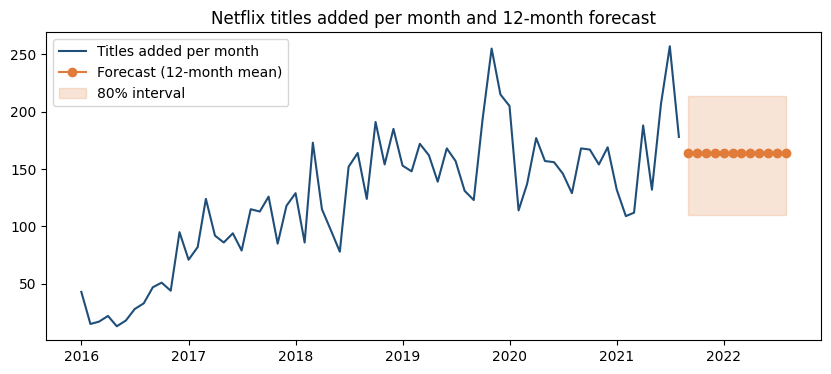

In [20]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(series.index, series.values, color="#1f4e79", label="Titles added per month")
ax.plot(forecast.index, forecast["forecast"], color="#e07b39", marker="o", label=f"Forecast ({winner})")
ax.fill_between(forecast.index, forecast["low_80"], forecast["high_80"], color="#e07b39", alpha=0.2, label="80% interval")
ax.set_title("Netflix titles added per month and 12-month forecast")
ax.legend()
plt.show()

### Notes
- The series is not flat noise. Monthly additions averaged 36 in 2016 and 168 in 2019, then stayed level (157 in 2020, 164 in 2021). The 12-month mean wins because growth stopped.
- MASE is above 1 for every model, baselines included. One-step naive error is 26.4 in the first 48 months and 34.0 in the test months, so the test period is noisier than the history it is scaled by. The gate is applied to the three candidate models only, and all three were rejected.
- The winner beats naive in 13 of 20 origins. The origins overlap, so this is modest evidence, and the test months (Jan 2020 to Aug 2021) include the pandemic swings.
- The ridge alpha is tuned inside each origin with `TimeSeriesSplit`, so it never sees future months.
- Result: a flat forecast of 164 titles a month, with an 80% interval of 110 to 214 taken from the winner's backtest errors.

## Task 6: Analytics engine
One pipeline from raw data to a report: stratified 80/20 split first, three models compared by 5-fold CV, the best one tuned, a decision threshold chosen on training data, a single holdout score, permutation importance, generated insights, and an HTML report with a saved model in `artifacts/`. The data has no views or reviews, so the target is a stated proxy: whether a title was added within one year of its release.

In [21]:
DATA = Path("netflix_titles.csv")

ARTIFACTS = Path("artifacts")

SEED = 42

FEATURES = ["is_tv", "duration_num", "n_genres", "director_known", "month_added",
            "rating", "primary_country", "first_director", "listed_in"]

LABELS = {"is_tv": "Movie or TV show", "duration_num": "Duration", "n_genres": "Number of genres",
          "director_known": "Director listed", "month_added": "Month added", "rating": "Rating",
          "primary_country": "Country", "first_director": "Director", "listed_in": "Genres"}

BLUE, ORANGE = "#1f4e79", "#e07b39"

def genre_tokens(text):
    return [g.strip() for g in text.split(",")]

class DataLoader:
    def __init__(self, path=DATA):
        self.path = path

    def load(self):
        df = pd.read_csv(self.path)
        added = pd.to_datetime(df["date_added"].str.strip(), format="%m/%d/%Y")
        df["year_added"] = added.dt.year
        df["month_added"] = added.dt.month
        df["duration_num"] = df["duration"].str.extract(r"(\d+)")[0].astype(int)
        df["is_tv"] = (df["type"] == "TV Show").astype(int)
        df["n_genres"] = df["listed_in"].str.count(",") + 1
        df["director_known"] = (df["director"] != "Not Given").astype(int)
        df["first_director"] = df["director"].where(df["director"] != "Not Given", "Unknown").str.split(",").str[0].str.strip()
        country = df["country"].where(df["country"] != "Not Given", "Unknown")
        df["primary_country"] = country.str.split(",").str[0].str.strip()
        df["fresh_release"] = (df["year_added"] - df["release_year"] <= 1).astype(int)
        return df

    def split(self, df):
        train, test = train_test_split(df, test_size=0.2, stratify=df["fresh_release"], random_state=SEED)
        return train, test

def build_engine_pipeline(model):
    prep = ColumnTransformer([
        ("num", StandardScaler(), ["duration_num", "n_genres", "month_added"]),
        ("flags", "passthrough", ["is_tv", "director_known"]),
        ("rating", OneHotEncoder(handle_unknown="ignore"), ["rating"]),
        ("high_cardinality", TargetEncoder(target_type="binary", random_state=SEED), ["primary_country", "first_director"]),
        ("genre", CountVectorizer(analyzer=genre_tokens, binary=True, min_df=30), "listed_in"),
    ], sparse_threshold=0)
    return Pipeline([("prep", prep), ("model", model)])

MODEL_FAMILIES = {
    "Logistic regression": (LogisticRegression(max_iter=3000), {"model__C": [0.01, 0.1, 1, 10, 100]}),
    "Random forest": (RandomForestClassifier(300, n_jobs=-1, random_state=SEED),
                      {"model__max_depth": [8, 12, 20, None], "model__min_samples_leaf": [1, 3, 6],
                       "model__max_features": ["sqrt", 0.3]}),
    "Gradient boosting": (HistGradientBoostingClassifier(random_state=SEED),
                          {"model__learning_rate": [0.03, 0.05, 0.1], "model__max_depth": [3, 5, 7, None],
                           "model__max_leaf_nodes": [15, 31, 63], "model__l2_regularization": [0.0, 0.5, 2.0],
                           "model__min_samples_leaf": [10, 20, 40]}),
}

class ModelSelector:
    def __init__(self, X, y):
        self.X, self.y = X, y
        self.cv = StratifiedKFold(5, shuffle=True, random_state=SEED)

    def compare(self):
        rows = []
        for name, (model, _) in MODEL_FAMILIES.items():
            r = cross_validate(build_engine_pipeline(clone(model)), self.X, self.y, cv=self.cv, scoring=["roc_auc", "accuracy"])
            rows.append({"model": name, "roc_auc": r["test_roc_auc"].mean(), "roc_auc_std": r["test_roc_auc"].std(),
                         "accuracy": r["test_accuracy"].mean()})
        self.comparison = pd.DataFrame(rows).sort_values("roc_auc", ascending=False).reset_index(drop=True)
        return self.comparison

    def tune(self):
        self.family = self.comparison.at[0, "model"]
        model, grid = MODEL_FAMILIES[self.family]
        size = int(np.prod([len(v) for v in grid.values()]))
        search = RandomizedSearchCV(build_engine_pipeline(clone(model)), grid, n_iter=min(12, size), scoring="roc_auc",
                                    cv=self.cv, random_state=SEED, n_jobs=1).fit(self.X, self.y)
        self.best, self.best_params, self.tuned_auc = search.best_estimator_, search.best_params_, search.best_score_
        return self.best

    def pick_threshold(self):
        oof = cross_val_predict(clone(self.best), self.X, self.y, cv=self.cv, method="predict_proba")[:, 1]
        grid = np.round(np.arange(0.30, 0.71, 0.01), 2)
        accuracy = np.array([accuracy_score(self.y, oof >= t) for t in grid])
        best = grid[np.flatnonzero(accuracy == accuracy.max())]
        self.threshold = float(best[np.argmin(np.abs(best - 0.5))])
        self.oof_accuracy = float(accuracy.max())
        return self.threshold

def insights(df, comparison, holdout, importance):
    out = []
    movie_share = (df["type"] == "Movie").mean()
    out.append(f"The catalog holds {len(df):,} titles: {movie_share:.0%} movies and {1 - movie_share:.0%} TV shows.")

    yearly = df[df["year_added"].between(2016, 2020)]["year_added"].value_counts().sort_index()
    out.append(f"Additions peaked in {yearly.idxmax()} with {yearly.max():,} titles. In 2020 there were {yearly[2020]:,}, "
               f"{yearly[2020] / yearly.max() - 1:+.0%} against that peak.")

    top3 = df["primary_country"].value_counts(normalize=True).head(3)
    out.append("Three countries supply " + f"{top3.sum():.0%} of titles: " + ", ".join(f"{c} ({s:.0%})" for c, s in top3.items()) + ".")

    early, late = df["year_added"].between(2017, 2018), df["year_added"].between(2020, 2021)
    us_early = (df.loc[early, "primary_country"] == "United States").mean()
    us_late = (df.loc[late, "primary_country"] == "United States").mean()
    out.append(f"The US share of new additions moved from {us_early:.0%} in 2017 to 2018 to {us_late:.0%} in 2020 to 2021.")

    genres = df.assign(genre=df["listed_in"].str.split(",")).explode("genre")
    genres["genre"] = genres["genre"].str.strip()
    big = genres["genre"].value_counts()
    big = big[big >= 150].index
    share = lambda mask: genres[genres.index.isin(df.index[mask])]["genre"].value_counts(normalize=True).reindex(big).fillna(0)
    shift = (share(late) - share(early)).sort_values()
    out.append(f"Biggest genre gain between those windows: {shift.index[-1]} ({shift.iloc[-1] * 100:+.1f} points of genre tags). "
               f"Biggest loss: {shift.index[0]} ({shift.iloc[0] * 100:+.1f} points).")

    mature = df["rating"].isin(["TV-MA", "R", "NC-17"]).mean()
    kids = df["rating"].isin(["TV-Y", "TV-Y7", "TV-Y7-FV", "TV-G", "G"]).mean()
    out.append(f"Mature-rated titles (TV-MA, R, NC-17) make up {mature:.0%} of the catalog and kids ratings make up {kids:.0%}.")

    fresh = df[df["year_added"].between(2016, 2021)].groupby("year_added")["fresh_release"].mean()
    out.append(f"The share of titles added within a year of release fell from {fresh.loc[2016]:.0%} in 2016 to {fresh.loc[2021]:.0%} in 2021.")

    months = df[df["year_added"].between(2017, 2020)].groupby(["year_added", "month_added"]).size().groupby("month_added").mean()
    names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
    out.append(f"Across 2017 to 2020 the busiest month for additions was {names[months.idxmax() - 1]} (about {months.max():.0f} titles) "
               f"and the quietest was {names[months.idxmin() - 1]} (about {months.min():.0f}).")

    top = importance.head(3).index.tolist()
    out.append(f"On held-out titles the model reaches ROC AUC {holdout['roc_auc']:.2f} and accuracy {holdout['accuracy']:.1%} "
               f"against {holdout['baseline']:.1%} for always guessing the majority class. "
               f"The biggest drivers are {top[0]}, {top[1]} and {top[2]}.")
    return out, fresh, shift

def to_b64(fig):
    buf = io.BytesIO()
    fig.savefig(buf, format="png", bbox_inches="tight", dpi=110)
    plt.close(fig)
    return base64.b64encode(buf.getvalue()).decode()

def make_figures(df, fresh, comparison, importance, y_test, proba, threshold):
    style = {"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25, "font.size": 9}
    figs = {}
    with plt.rc_context(style):
        yearly = df[df["year_added"] >= 2014].groupby(["year_added", "type"]).size().unstack(fill_value=0)
        fig, ax = plt.subplots(figsize=(7, 3.2))
        yearly.plot(kind="bar", stacked=True, ax=ax, color=[BLUE, ORANGE], width=0.8)
        ax.set(title="Titles added per year (2021 runs to 25 Sep)", xlabel="", ylabel="Titles")
        ax.legend(title="")
        figs["added"] = to_b64(fig)

        fig, ax = plt.subplots(figsize=(7, 3))
        ax.plot(fresh.index, fresh.values * 100, marker="o", color=BLUE)
        ax.set(title="Share of titles added within a year of release (%)", xlabel="Year added", ylim=(0, 100))
        figs["fresh"] = to_b64(fig)

        fig, ax = plt.subplots(figsize=(7, 2.6))
        ordered = comparison.iloc[::-1]
        ax.barh(ordered["model"], ordered["roc_auc"], xerr=ordered["roc_auc_std"], color=BLUE)
        ax.set(title="Model comparison, 5-fold CV ROC AUC on the training set", xlim=(0.5, 0.9))
        figs["models"] = to_b64(fig)

        fig, ax = plt.subplots(figsize=(4.2, 3.6))
        RocCurveDisplay.from_predictions(y_test, proba, ax=ax, color=BLUE)
        ax.plot([0, 1], [0, 1], "--", color="grey")
        ax.set(title="Holdout ROC curve")
        figs["roc"] = to_b64(fig)

        matrix = confusion_matrix(y_test, proba >= threshold)
        fig, ax = plt.subplots(figsize=(4.2, 3.6))
        ax.imshow(matrix, cmap="Blues")
        ax.grid(False)
        for (i, j), n in np.ndenumerate(matrix):
            ax.text(j, i, n, ha="center", va="center", color="white" if n > matrix.max() / 2 else "black")
        ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["Back-catalog", "Fresh"], yticklabels=["Back-catalog", "Fresh"],
               xlabel="Predicted", ylabel="Actual", title=f"Holdout confusion matrix (threshold {threshold:.2f})")
        figs["confusion"] = to_b64(fig)

        fig, ax = plt.subplots(figsize=(7, 3.2))
        ax.barh(importance.index[::-1], importance.values[::-1], color=ORANGE)
        ax.set(title="Permutation importance on the holdout (drop in ROC AUC)", xlabel="AUC drop")
        figs["importance"] = to_b64(fig)
    return figs

REPORT = Template("""<!doctype html><html lang="en"><head><meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1"><title>Netflix content analytics</title>
<style>
body{font-family:Segoe UI,Arial,sans-serif;max-width:900px;margin:2rem auto;padding:0 1rem;color:#1c1c1c;line-height:1.5}
h1,h2{color:#1f4e79}h2{border-bottom:2px solid #e07b39;padding-bottom:4px;margin-top:2rem}
table{border-collapse:collapse;width:100%}th,td{border:1px solid #ddd;padding:6px 10px;text-align:right}
th{background:#1f4e79;color:#fff}td:first-child,th:first-child{text-align:left}
.kpi{display:flex;gap:12px;flex-wrap:wrap}.kpi div{flex:1;min-width:140px;background:#f2f6fa;padding:12px;border-radius:8px}
.kpi b{display:block;font-size:1.5rem;color:#1f4e79}.note{background:#fff6ee;border-left:4px solid #e07b39;padding:10px 14px}
img{max-width:100%}.row{display:flex;gap:12px;flex-wrap:wrap}
</style></head><body>
<h1>Netflix content analytics</h1>
<h2>Findings</h2><ul>{% for line in insights %}<li>{{ line }}</li>{% endfor %}</ul>
<h2>Catalog trends</h2><img src="data:image/png;base64,{{ figs.added }}"><img src="data:image/png;base64,{{ figs.fresh }}">
<h2>Predicting fresh releases</h2>
<p class="note">The data has no views or review scores. The model predicts whether a title was added within one year of its release. This separates current content from back-catalog and does not measure audience success.</p>
<div class="kpi">
<div><b>{{ "%.3f"|format(holdout.roc_auc) }}</b>Holdout ROC AUC</div>
<div><b>{{ "%.1f"|format(holdout.accuracy * 100) }}%</b>Holdout accuracy</div>
<div><b>{{ "%.1f"|format(holdout.baseline * 100) }}%</b>Majority-class accuracy</div>
<div><b>{{ "%.3f"|format(holdout.f1) }}</b>Holdout F1</div></div>
<h3>Model comparison</h3>{{ comparison_table }}<img src="data:image/png;base64,{{ figs.models }}">
<p>Selected: {{ family }} with {{ params }}. Decision threshold {{ "%.2f"|format(threshold) }}, chosen on out-of-fold training predictions. Accuracy at 0.50 on the holdout was {{ "%.1f"|format(holdout.accuracy_at_half * 100) }}%.</p>
<div class="row"><img src="data:image/png;base64,{{ figs.roc }}" style="width:320px"><img src="data:image/png;base64,{{ figs.confusion }}" style="width:320px"></div>
<h3>What drives the prediction</h3><img src="data:image/png;base64,{{ figs.importance }}">
<h2>Notes</h2><ul>
<li>The holdout is a stratified 20% split made before any fitting. It was scored once.</li>
<li>Release year and year added are left out of the features because they define the target.</li>
<li>Country and director are encoded with out-of-fold target encoding inside the pipeline.</li>
<li>Importance shows association, not cause.</li>
<li>Trend figures use the full catalog. 2021 covers January to 25 September.</li></ul>
</body></html>""")

In [22]:
ARTIFACTS.mkdir(exist_ok=True)
loader = DataLoader()
titles = loader.load()
train6, test6 = loader.split(titles)
X6_train, y6_train, X6_test, y6_test = train6[FEATURES], train6["fresh_release"], test6[FEATURES], test6["fresh_release"]
print(f"{len(titles)} titles | fresh_release rate {titles['fresh_release'].mean():.1%} | train {len(train6)} | holdout {len(test6)}")

8790 titles | fresh_release rate 55.0% | train 7032 | holdout 1758


In [23]:
selector = ModelSelector(X6_train, y6_train)
comparison = selector.compare()
print("Cross-validated comparison on the training set:")
print(comparison.round(3).to_string(index=False))
best = selector.tune()
print(f"\nTuned {selector.family}: CV ROC AUC {selector.tuned_auc:.3f} with { {k.replace('model__', ''): v for k, v in selector.best_params.items()} }")
threshold = selector.pick_threshold()
print(f"Threshold {threshold:.2f} chosen on out-of-fold training predictions (accuracy {selector.oof_accuracy:.3f})")

Cross-validated comparison on the training set:
              model  roc_auc  roc_auc_std  accuracy
  Gradient boosting    0.792        0.010     0.729
      Random forest    0.786        0.009     0.732
Logistic regression    0.778        0.011     0.724



Tuned Gradient boosting: CV ROC AUC 0.791 with {'min_samples_leaf': 20, 'max_leaf_nodes': 63, 'max_depth': 5, 'learning_rate': 0.1, 'l2_regularization': 0.5}


Threshold 0.49 chosen on out-of-fold training predictions (accuracy 0.733)


In [24]:
proba = best.predict_proba(X6_test)[:, 1]
pred6 = proba >= threshold
holdout = {"roc_auc": roc_auc_score(y6_test, proba), "accuracy": accuracy_score(y6_test, pred6),
           "accuracy_at_half": accuracy_score(y6_test, proba >= 0.5), "f1": f1_score(y6_test, pred6),
           "baseline": max(y6_test.mean(), 1 - y6_test.mean())}
print(f"Holdout, scored once: ROC AUC {holdout['roc_auc']:.3f} | accuracy {holdout['accuracy']:.3f} "
      f"(0.50 threshold: {holdout['accuracy_at_half']:.3f}) | F1 {holdout['f1']:.3f} | majority baseline {holdout['baseline']:.3f}")
result = permutation_importance(best, X6_test, y6_test, scoring="roc_auc", n_repeats=10, random_state=SEED)
importance = pd.Series(result.importances_mean, index=[LABELS[c] for c in FEATURES]).sort_values(ascending=False)
print("\nPermutation importance (drop in holdout ROC AUC):")
print(importance.round(4).to_string())

Holdout, scored once: ROC AUC 0.784 | accuracy 0.717 (0.50 threshold: 0.718) | F1 0.763 | majority baseline 0.550



Permutation importance (drop in holdout ROC AUC):
Rating              0.1181
Country             0.0556
Genres              0.0445
Director            0.0212
Month added         0.0098
Duration            0.0093
Number of genres    0.0010
Director listed     0.0005
Movie or TV show    0.0000


In [25]:
lines6, fresh, _ = insights(titles, comparison, holdout, importance)
for line in lines6:
    print("-", line)

- The catalog holds 8,790 titles: 70% movies and 30% TV shows.
- Additions peaked in 2019 with 2,016 titles. In 2020 there were 1,879, -7% against that peak.
- Three countries supply 56% of titles: United States (37%), India (12%), United Kingdom (7%).
- The US share of new additions moved from 32% in 2017 to 2018 to 38% in 2020 to 2021.
- Biggest genre gain between those windows: Comedies (+2.1 points of genre tags). Biggest loss: International Movies (-3.8 points).
- Mature-rated titles (TV-MA, R, NC-17) make up 46% of the catalog and kids ratings make up 10%.
- The share of titles added within a year of release fell from 66% in 2016 to 51% in 2021.
- Across 2017 to 2020 the busiest month for additions was Dec (about 172 titles) and the quietest was Feb (about 108).
- On held-out titles the model reaches ROC AUC 0.78 and accuracy 71.7% against 55.0% for always guessing the majority class. The biggest drivers are Rating, Country and Genres.


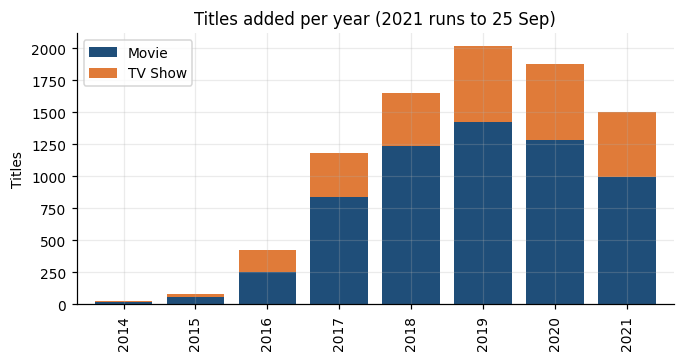

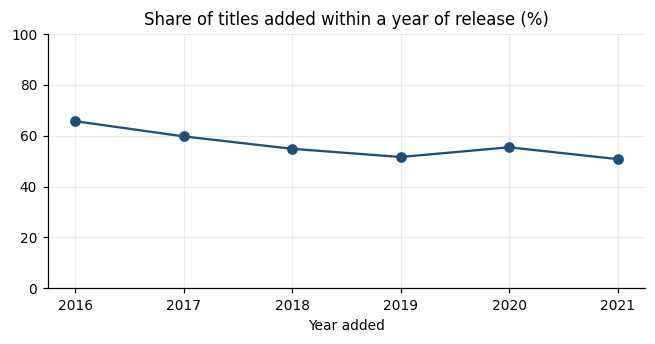

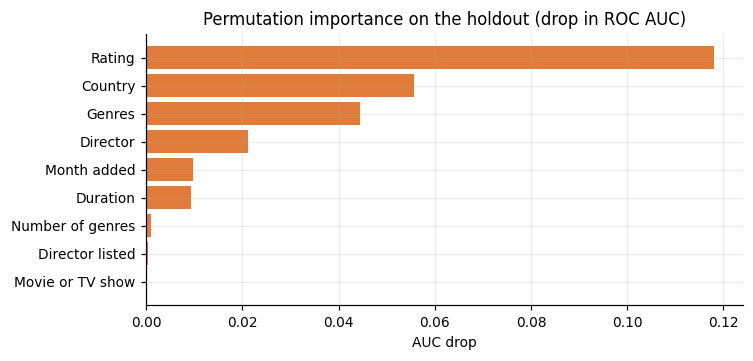

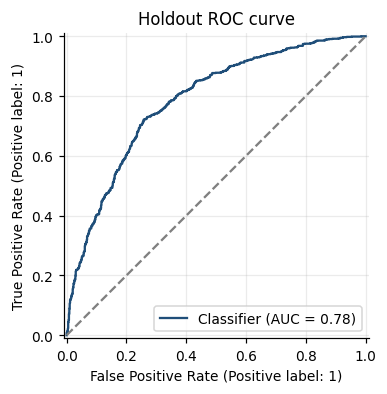

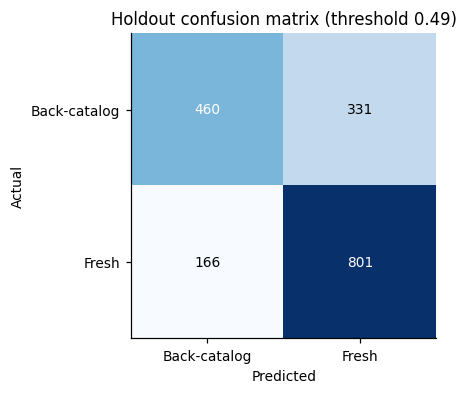

Wrote artifacts/report.html and artifacts/model.joblib


In [26]:
figs = make_figures(titles, fresh, comparison, importance, y6_test, proba, threshold)
for key in ["added", "fresh", "importance", "roc", "confusion"]:
    display(Image(data=base64.b64decode(figs[key])))
table6 = comparison.rename(columns={"model": "Model", "roc_auc": "CV ROC AUC", "roc_auc_std": "Std", "accuracy": "CV accuracy"})
params6 = ", ".join(f"{k.replace('model__', '')}={v}" for k, v in selector.best_params.items())
html = REPORT.render(insights=lines6, figs=figs, holdout=holdout, family=selector.family, params=params6,
                     threshold=threshold, comparison_table=table6.to_html(index=False, float_format=lambda v: f"{v:.3f}"))
(ARTIFACTS / "report.html").write_text(html, encoding="utf-8")
joblib.dump({"model": best, "threshold": threshold, "features": FEATURES}, ARTIFACTS / "model.joblib")
print("Wrote artifacts/report.html and artifacts/model.joblib")

### Notes
- The reference plan said to tune the threshold to lock in 69.9% accuracy. That figure was measured on the holdout, so doing so would fit the threshold to the test set. The threshold (0.49) is chosen on out-of-fold training predictions and the holdout is scored once.
- Holdout ROC AUC is 0.784 and accuracy 71.7%, against 55.0% for the majority class. Accuracy is higher than 69.9% after adding target-encoded country and director to the features. At a 0.50 threshold it is 71.8%, so the threshold barely matters.
- Release year and year added define the target and are excluded from the features.
- Permutation importance replaces SHAP. Rating is the largest driver (0.118 drop in AUC), then country, genres and director. Importance shows association, not cause.
- The proxy separates current content from back-catalog. It does not measure audience success.